# GAD-7 Regression RL Model (Valence)
This model isolates the Valence framework (Model 2) and tests whether generalized anxiety symptoms (GAD-7) linearly predict the positive and negative learning rates.
Instead of allowing free individual variation, learning rates are strictly parameterized by GAD-7:
`alpha_pos(sub) = invlogit(intercept_pos + slope_pos * GAD7_normalized(sub))`
`alpha_neg(sub) = invlogit(intercept_neg + slope_neg * GAD7_normalized(sub))`

We extract the 89% Highest Density Interval (HDI) for the slopes to determine if the effect is credible.


In [1]:
import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
from scipy import stats
import warnings

from learning_functions import prepare_vectorized_bandit_data, step_m2_vec, get_hdi_bounds, plot_posterior_hdi

warnings.filterwarnings('ignore')


In [2]:
# Load Data and Vectorize across Subjects
file_path = '../data/allsubs_combined.csv'
df_raw = pd.read_csv(file_path).dropna(subset=['ChoiceKey', 'GAD7']).reset_index(drop=True).copy()

stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df_raw['LeftID_int'] = df_raw['LeftID'].map(stim_map)
df_raw['RightID_int'] = df_raw['RightID'].map(stim_map)
df_raw['ChosenID_int'] = df_raw['ChosenID'].map(stim_map)
df_raw['Choice'] = (df_raw['ChoiceKey'] - 1).astype(int)
df_raw['RewardScaled'] = df_raw['TrialPoints'] / 30.0

vdata = prepare_vectorized_bandit_data(df_raw)
df = vdata['df']
n_sub = vdata['n_sub']
unique_subs = vdata['unique_subs']

sub_gad7_map = df.groupby('SubIdx')['GAD7'].first()
gad7_scores = np.array([sub_gad7_map[i] for i in range(n_sub)])
gad7_normalized = gad7_scores / 21.0

print(f"Total subjects included: {n_sub}")
print(f"Total trials: {len(df)} (Vectorized scan length: {vdata['max_t']} steps)")


Total subjects included: 67
Total trials: 6520 (Vectorized scan length: 100 steps)


In [3]:
def build_gad7_model(vdata, gad7_normalized):
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as m_gad7:
        gad7_data = pm.Data("gad7_data", gad7_normalized)
        
        intercept_pos = pm.Normal('intercept_pos', mu=0, sigma=1.5)
        slope_pos = pm.Normal('slope_pos', mu=0, sigma=1.5)
        
        intercept_neg = pm.Normal('intercept_neg', mu=0, sigma=1.5)
        slope_neg = pm.Normal('slope_neg', mu=0, sigma=1.5)
        
        alpha_pos = pm.Deterministic('alpha_pos', pm.math.invlogit(intercept_pos + slope_pos * gad7_data))
        alpha_neg = pm.Deterministic('alpha_neg', pm.math.invlogit(intercept_neg + slope_neg * gad7_data))
        
        mu_beta_log = pm.Normal('mu_beta_log', mu=0, sigma=2.0)
        sigma_beta = pm.HalfNormal('sigma_beta', sigma=1.0)
        beta_raw = pm.Normal('beta_raw', mu=0, sigma=1, shape=n_sub)
        beta = pm.Deterministic('beta', pm.math.exp(mu_beta_log + beta_raw * sigma_beta))
        
        Q_init = pt.zeros((n_sub, 4))
        results = pytensor.scan(
            fn=step_m2_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
            ],
            outputs_info=[Q_init, None, None, None],
            non_sequences=[alpha_pos, alpha_neg],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[1][t_idx, s_idx]
        q_right_seq = results[2][t_idx, s_idx]
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return m_gad7

print("Building vectorized model...")
m_gad7 = build_gad7_model(vdata, gad7_normalized)


Building vectorized model...


In [4]:
print("Sampling posterior using nutpie (PyMC 6)...")
with m_gad7:
    idata = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
print("Sampling complete!")


Sampling posterior using nutpie (PyMC 6)...


NUTS[nutpie]: [intercept_pos, slope_pos, intercept_neg, slope_neg, mu_beta_log, sigma_beta, beta_raw]


Output()

Sampling complete!


GAD-7 REGRESSION RESULTS (89% HDI)
Slope Positive (alpha_pos) HDI 89%: [1.813, 4.420] -> EXCLUDES 0 (Credible effect at 89%)
Slope Negative (alpha_neg) HDI 89%: [-1.030, 0.294] -> INCLUDES 0 (Not strictly credible at 89%)



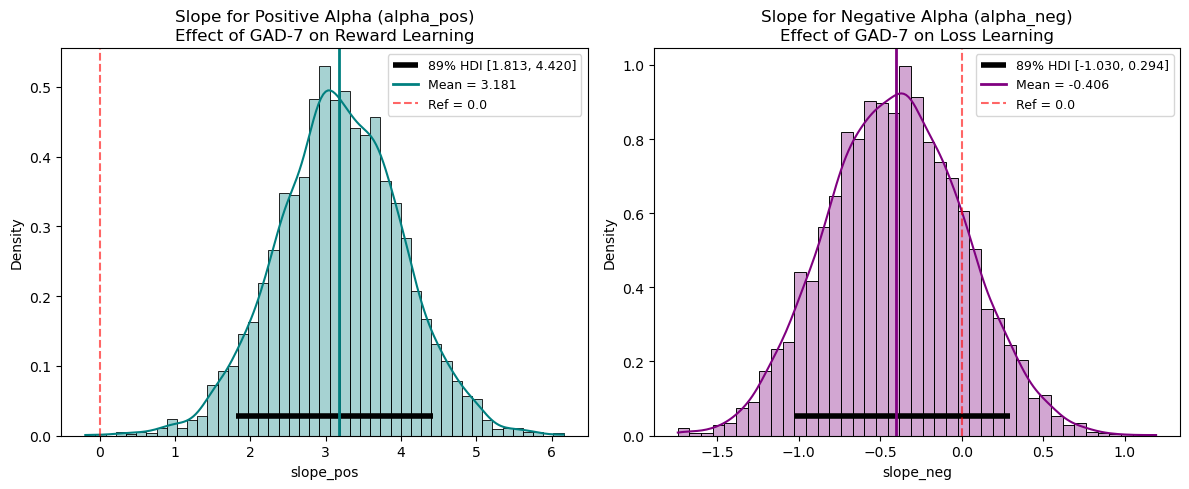

In [5]:
sp_low, sp_high = get_hdi_bounds(idata, 'slope_pos', prob=0.89)
sn_low, sn_high = get_hdi_bounds(idata, 'slope_neg', prob=0.89)

def check_credibility(low, high, param_name):
    includes_zero = (low <= 0) and (high >= 0)
    status = "INCLUDES 0 (Not strictly credible at 89%)" if includes_zero else "EXCLUDES 0 (Credible effect at 89%)"
    print(f"{param_name} HDI 89%: [{low:.3f}, {high:.3f}] -> {status}")

print("==================================================")
print("GAD-7 REGRESSION RESULTS (89% HDI)")
print("==================================================")
check_credibility(sp_low, sp_high, "Slope Positive (alpha_pos)")
check_credibility(sn_low, sn_high, "Slope Negative (alpha_neg)")
print("==================================================\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_posterior_hdi(idata, 'slope_pos', prob=0.89, ax=axes[0], color="teal", title="Slope for Positive Alpha (alpha_pos)\nEffect of GAD-7 on Reward Learning")
plot_posterior_hdi(idata, 'slope_neg', prob=0.89, ax=axes[1], color="purple", title="Slope for Negative Alpha (alpha_neg)\nEffect of GAD-7 on Loss Learning")
plt.tight_layout()
plt.show()


CORRELATION BETWEEN ALPHA_POS AND ALPHA_NEG (NOTEBOOK 06 MODEL)
1. Subject-Level Posterior Means (N = 67, parameterized by GAD-7):
   Pearson r  = -0.9982 (p = 8.6101e-81)
   Spearman r = -1.0000 (p = 0.0000e+00)

2. Posterior Draw-Level Correlation (4,000 MCMC draws):
   Mean alpha_pos vs. Mean alpha_neg: Pearson r = -0.1871 (p = 7.9147e-33)
   slope_pos vs. slope_neg:           Pearson r = -0.1489 (p = 2.9079e-21)



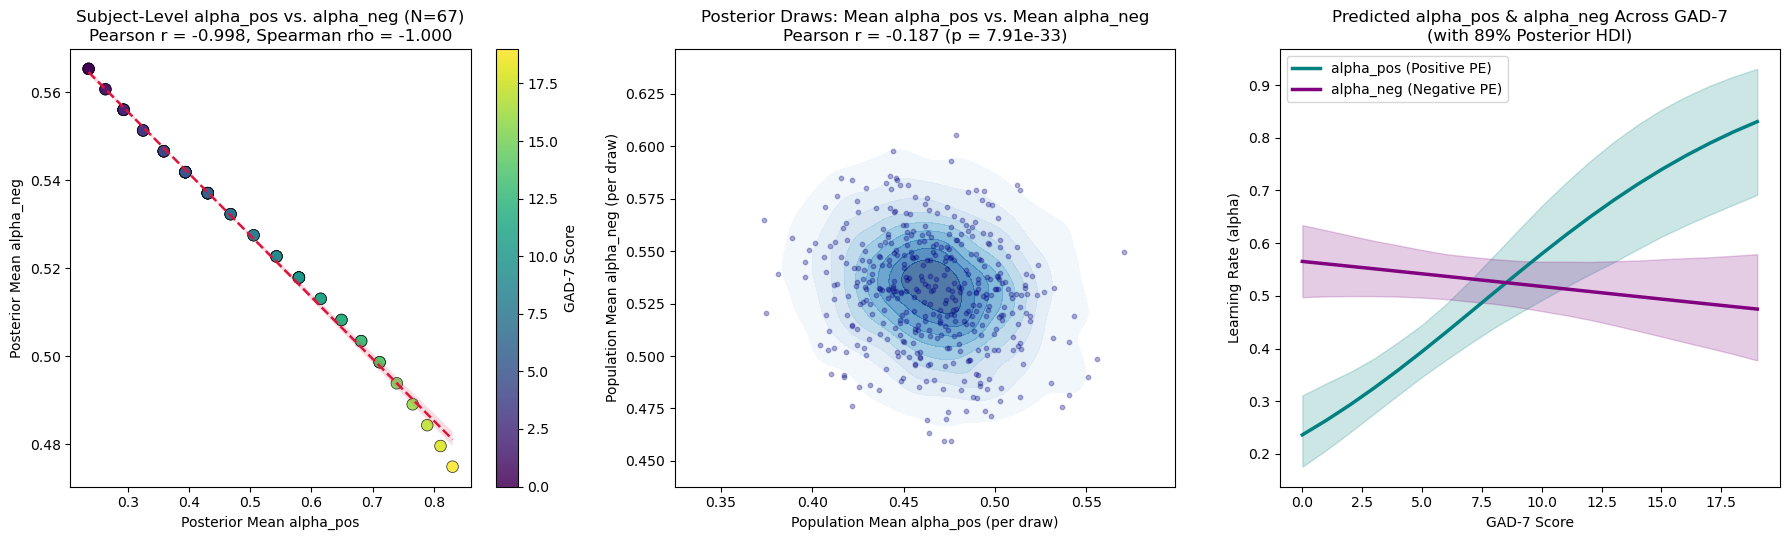

In [6]:
import seaborn as sns
from scipy import stats

# Extract subject-level posterior means and 89% HDIs for alpha_pos and alpha_neg
alpha_pos_samples = idata.posterior['alpha_pos'].values.reshape(-1, n_sub)  # (n_draws, n_sub)
alpha_neg_samples = idata.posterior['alpha_neg'].values.reshape(-1, n_sub)  # (n_draws, n_sub)

alpha_pos_mean = alpha_pos_samples.mean(axis=0)
alpha_neg_mean = alpha_neg_samples.mean(axis=0)

# Draw-level mean learning rates across subjects (4000 posterior draws)
draw_mean_pos = alpha_pos_samples.mean(axis=1)
draw_mean_neg = alpha_neg_samples.mean(axis=1)

# Correlations
r_sub, p_sub = stats.pearsonr(alpha_pos_mean, alpha_neg_mean)
rho_sub, prho_sub = stats.spearmanr(alpha_pos_mean, alpha_neg_mean)

r_draw, p_draw = stats.pearsonr(draw_mean_pos, draw_mean_neg)
slope_pos_draws = idata.posterior['slope_pos'].values.flatten()
slope_neg_draws = idata.posterior['slope_neg'].values.flatten()
r_slope, p_slope = stats.pearsonr(slope_pos_draws, slope_neg_draws)

print("==================================================================")
print("CORRELATION BETWEEN ALPHA_POS AND ALPHA_NEG (NOTEBOOK 06 MODEL)")
print("==================================================================")
print(f"1. Subject-Level Posterior Means (N = {n_sub}, parameterized by GAD-7):")
print(f"   Pearson r  = {r_sub:.4f} (p = {p_sub:.4e})")
print(f"   Spearman r = {rho_sub:.4f} (p = {prho_sub:.4e})")
print(f"\n2. Posterior Draw-Level Correlation (4,000 MCMC draws):")
print(f"   Mean alpha_pos vs. Mean alpha_neg: Pearson r = {r_draw:.4f} (p = {p_draw:.4e})")
print(f"   slope_pos vs. slope_neg:           Pearson r = {r_slope:.4f} (p = {p_slope:.4e})")
print("==================================================================\n")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel 1: Subject-level alpha_pos vs alpha_neg colored by GAD-7
sc = axes[0].scatter(alpha_pos_mean, alpha_neg_mean, c=gad7_scores, cmap='viridis', s=70, alpha=0.85, edgecolors='k', linewidth=0.5)
sns.regplot(x=alpha_pos_mean, y=alpha_neg_mean, ax=axes[0], scatter=False, color='crimson', line_kws={'linestyle': '--', 'linewidth': 1.8})
cbar = plt.colorbar(sc, ax=axes[0])
cbar.set_label('GAD-7 Score')
axes[0].set_title(f"Subject-Level alpha_pos vs. alpha_neg (N={n_sub})\nPearson r = {r_sub:.3f}, Spearman rho = {rho_sub:.3f}")
axes[0].set_xlabel("Posterior Mean alpha_pos")
axes[0].set_ylabel("Posterior Mean alpha_neg")

# Panel 2: Posterior Draw-Level Mean alpha_pos vs Mean alpha_neg
sns.kdeplot(x=draw_mean_pos, y=draw_mean_neg, ax=axes[1], cmap="Blues", fill=True, thresh=0.05, alpha=0.7)
axes[1].scatter(draw_mean_pos[::10], draw_mean_neg[::10], color='navy', s=10, alpha=0.3)
axes[1].set_title(f"Posterior Draws: Mean alpha_pos vs. Mean alpha_neg\nPearson r = {r_draw:.3f} (p = {p_draw:.2e})")
axes[1].set_xlabel("Population Mean alpha_pos (per draw)")
axes[1].set_ylabel("Population Mean alpha_neg (per draw)")

# Panel 3: Both learning rates as a function of GAD-7 with 89% HDI
sort_idx = np.argsort(gad7_scores)
g_sorted = gad7_scores[sort_idx]
pos_hdi = np.quantile(alpha_pos_samples[:, sort_idx], [0.055, 0.945], axis=0).T
neg_hdi = np.quantile(alpha_neg_samples[:, sort_idx], [0.055, 0.945], axis=0).T

axes[2].plot(g_sorted, alpha_pos_mean[sort_idx], color='teal', lw=2.5, label='alpha_pos (Positive PE)')
axes[2].fill_between(g_sorted, pos_hdi[:, 0], pos_hdi[:, 1], color='teal', alpha=0.2)
axes[2].plot(g_sorted, alpha_neg_mean[sort_idx], color='purple', lw=2.5, label='alpha_neg (Negative PE)')
axes[2].fill_between(g_sorted, neg_hdi[:, 0], neg_hdi[:, 1], color='purple', alpha=0.2)
axes[2].set_title("Predicted alpha_pos & alpha_neg Across GAD-7\n(with 89% Posterior HDI)")
axes[2].set_xlabel("GAD-7 Score")
axes[2].set_ylabel("Learning Rate (alpha)")
axes[2].legend(loc='best')

plt.tight_layout()
plt.savefig('../data/alpha_pos_vs_alpha_neg_nb06.png', dpi=150, bbox_inches='tight')
plt.show()
